<a href="https://colab.research.google.com/github/jlen0011-eng/Count_Apple/blob/main/Apple2210.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mount Google Drive and Persist Dataset
Running the code below will prompt you to authorize Google Drive access. Once mounted, we can copy the file to your Drive for permanent storage.

In [30]:
!git clone https://github.com/jlen0011-eng/Count_Apple.git

Cloning into 'Count_Apple'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 28 (delta 7), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 5.70 MiB | 15.65 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [31]:
%cd Count_Apple
!ls

/content/Count_Apple/Count_Apple/Count_Apple
Apple2210.ipynb  LICENSE  README.md


In [32]:
!pwd
!ls -la

/content/Count_Apple/Count_Apple/Count_Apple
total 2352
drwxr-xr-x 3 root root    4096 Oct 25 05:02 .
drwxr-xr-x 4 root root    4096 Oct 25 05:02 ..
-rw-r--r-- 1 root root 2382612 Oct 25 05:02 Apple2210.ipynb
drwxr-xr-x 8 root root    4096 Oct 25 05:02 .git
-rw-r--r-- 1 root root      35 Oct 25 05:02 .gitignore
-rw-r--r-- 1 root root    1069 Oct 25 05:02 LICENSE
-rw-r--r-- 1 root root      13 Oct 25 05:02 README.md


In [33]:
from google.colab import drive
import os

# Mount Google Drive (already mounted is fine)
drive.mount('/content/drive')

# Define the path to your unzipped dataset
dataset_path = '/content/drive/MyDrive/Colab_Datasets/Dataset'

# Check that the folder exists
if os.path.isdir(dataset_path):
    print("Dataset folder found!")
    print(os.listdir(dataset_path)[:20])
else:
    print("Dataset folder not found. Check the path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder found!
['R11U05_Summer_D-13-41-43.png', 'R09U09_Summer_D-13-33-30.png', 'R10U13_Winter_D-12-12-10.png', 'R08U04_Winter_RGB-12-01-18.png', 'R11U04_Winter_D-12-14-54.png', 'R08U21_Winter_D-12-03-08.png', 'R07U13_Summer_RGB-13-23-17.png', 'R07U16_Summer_RGB-13-23-33.png', 'R09U07_Winter_D-12-06-31.png', 'R08U01_Winter_RGB-12-01-03.png', 'R09U05_Summer_D-13-31-47.png', 'R09U03_Summer_D-13-31-23.png', 'R08U15_Summer_D-13-27-2.png', 'R10U06_Summer_D-13-38-9.png', 'R09U05_Winter_D-12-05-59.png', 'R08U15_Winter_D-12-02-15.png', 'R12U06_Summer_D-13-46-37.png', 'R10U07_Winter_RGB-12-11-28.png', 'R08U23_Winter_RGB-12-03-15.png', 'R09U01_Summer_D-13-30-56.png']


### Extract Dataset and Split into Train, Test, and Validation Sets
We will extract the contents of the zip file, create the `summer_rgb` and `summer_d` directories, and then split the files into `train` (70%), `test` (15%), and `val` (15%) subfolders.

In [34]:
import subprocess
import os

# Let's check the local source file on Colab's temporary storage
local_zip = '/content/Dataset-20260930T233804Z-1-001.zip'
extract_path = '/content/extracted_dataset'

print("Checking local source file:")
if os.path.exists(local_zip):
    print(f"Local file size: {os.path.getsize(local_zip)} bytes")
    result = subprocess.run(['file', local_zip], capture_output=True, text=True)
    print("Local file type analysis:", result.stdout.strip())

    # Attempt to unzip the original local file directly
    os.makedirs(extract_path, exist_ok=True)
    print("\nAttempting extraction of local file...")
    res_unzip = subprocess.run(['unzip', '-q', local_zip, '-d', extract_path], capture_output=True, text=True)
    if res_unzip.returncode == 0:
        print("Successfully extracted local file!")
    else:
        print("Local unzip failed. Error:\n", res_unzip.stderr)
else:
    print("Local file /content/Dataset-20260930T233804Z-1-001.zip does not exist.")

Checking local source file:
Local file /content/Dataset-20260930T233804Z-1-001.zip does not exist.


In [35]:
import os
import glob
import random
import shutil

base_dir = '/content/split_dataset'
# Read directly from the unzipped Google Drive folder location
extract_path = '/content/drive/MyDrive/Colab_Datasets/Dataset'
subfolders = ['summer_rgb', 'summer_d']
splits = ['train', 'test', 'val']

# Create clean target directory structure in local workspace
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)
for sub in subfolders:
    for s in splits:
        os.makedirs(os.path.join(base_dir, sub, s), exist_ok=True)

# Recursively find all image files in the Google Drive folder
all_files = glob.glob(os.path.join(extract_path, '**', '*'), recursive=True)
all_images = [f for f in all_files if os.path.isfile(f) and f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]

# Filter strictly for 'Summer' files
summer_images = [img for img in all_images if 'summer' in os.path.basename(img).lower()]

# Separate into rgb and depth (d) strictly for Summer
rgb_images = [img for img in summer_images if 'rgb' in os.path.basename(img).lower() or 'color' in os.path.basename(img).lower()]
d_images = [img for img in summer_images if '_d-' in os.path.basename(img).lower() or 'depth' in os.path.basename(img).lower()]

print(f"Total images found: {len(all_images)}")
print(f"Summer-only images: {len(summer_images)}")
print(f" -> Summer RGB: {len(rgb_images)}")
print(f" -> Summer Depth (D): {len(d_images)}")

def split_and_copy(images, category):
    if not images:
        print(f"\nNo images to process for {category}")
        return

    random.seed(42)
    random.shuffle(images)

    n = len(images)
    n_train = int(n * 0.75)
    n_test = int(n * 0.15)

    train_imgs = images[:n_train]
    test_imgs = images[n_train:n_train + n_test]
    val_imgs = images[n_train + n_test:]

    for img_set, split_name in zip([train_imgs, test_imgs, val_imgs], ['train', 'test', 'val']):
        dest_path = os.path.join(base_dir, category, split_name)
        for img in img_set:
            shutil.copy(img, os.path.join(dest_path, os.path.basename(img)))

    print(f"\n{category.upper()} split complete:")
    print(f" - Train (75%): {len(train_imgs)}")
    print(f" - Test (15%): {len(test_imgs)}")
    print(f" - Val (10%): {len(val_imgs)}")

split_and_copy(rgb_images, 'summer_rgb')
split_and_copy(d_images, 'summer_d')

Total images found: 2176
Summer-only images: 1088
 -> Summer RGB: 544
 -> Summer Depth (D): 544

SUMMER_RGB split complete:
 - Train (75%): 408
 - Test (15%): 81
 - Val (10%): 55

SUMMER_D split complete:
 - Train (75%): 408
 - Test (15%): 81
 - Val (10%): 55


### 1. Match RGB and Depth Images & Create Ground Truth Labels
Since this dataset does not come with explicit count labels, we can dynamically simulate or find apple count labels, or define a reliable pipeline where you can insert your count labels. For the purpose of training a regression CNN, we will first create an aligned list of matching RGB and Depth pairs, and build a PyTorch `Dataset` that filters RGB pixels using the corresponding Depth map.

In [36]:
import os
import glob
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from PIL import Image

def get_aligned_pairs(split_dir, split_name):
    rgb_dir = os.path.join(split_dir, 'summer_rgb', split_name)
    d_dir = os.path.join(split_dir, 'summer_d', split_name)

    rgb_files = sorted(glob.glob(os.path.join(rgb_dir, '*.png')))
    d_files = sorted(glob.glob(os.path.join(d_dir, '*.png')))

    pairs = []
    # Map the unique identifier prefix (e.g., 'R01U02') to its depth file
    d_dict = {}
    for d_path in d_files:
        base = os.path.basename(d_path)
        prefix = base.split('_Summer')[0]
        d_dict[prefix] = d_path

    for rgb_path in rgb_files:
        base = os.path.basename(rgb_path)
        prefix = base.split('_Summer')[0]
        if prefix in d_dict:
            pairs.append((rgb_path, d_dict[prefix]))

    return pairs

base_dir = '/content/split_dataset'
train_pairs = get_aligned_pairs(base_dir, 'train')
val_pairs = get_aligned_pairs(base_dir, 'val')
test_pairs = get_aligned_pairs(base_dir, 'test')

print(f"Matched Pairs - Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}")

Matched Pairs - Train: 312, Val: 7, Test: 16


### 2. Custom Dataset with Depth-Gating
We will define a custom PyTorch Dataset. To strictly look at foreground objects, we normalize the depth image and use it as a soft mask (gate) on the RGB image. Pixels that are far away (darker in depth map) will be suppressed, while pixels belonging to the target tree (lighter in depth map) are preserved.

In [37]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image

class AppleCountingDataset(Dataset):
    def __init__(self, pairs, transform=None, is_train=True):
        self.pairs = pairs
        self.transform = transform

        # Synthesize dummy labels (counts) for demonstration since explicit counts aren't provided.
        # In practice, replace this with your ground truth count vector.
        np.random.seed(42)
        self.labels = np.random.randint(5, 50, size=len(pairs)).astype(np.float32)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        rgb_path, d_path = self.pairs[idx]

        # Load images
        rgb_img = Image.open(rgb_path).convert('RGB')
        d_img = Image.open(d_path).convert('L') # Load depth as single-channel grayscale

        if self.transform:
            rgb_tensor = self.transform(rgb_img)
            d_tensor = transforms.ToTensor()(d_img)
            # Resize depth to match RGB if different
            if d_tensor.shape[1:] != rgb_tensor.shape[1:]:
                d_tensor = transforms.Resize(rgb_tensor.shape[1:], interpolation=transforms.InterpolationMode.NEAREST)(d_img)
                d_tensor = transforms.ToTensor()(d_tensor)
        else:
            rgb_tensor = transforms.ToTensor()(rgb_img)
            d_tensor = transforms.ToTensor()(d_img)

        # Depth gating: Use light areas of depth (> threshold or scaled multiplier) to mask the background
        # Normalizing depth map to [0, 1]
        depth_mask = d_tensor / (d_tensor.max() + 1e-8)

        # Mask out background from RGB representation
        gated_rgb = rgb_tensor * depth_mask

        label = self.labels[idx]
        return gated_rgb, torch.tensor(label, dtype=torch.float32)

# Define simple image transform
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

train_dataset = AppleCountingDataset(train_pairs, transform=transform, is_train=True)
val_dataset = AppleCountingDataset(val_pairs, transform=transform, is_train=False)
test_dataset = AppleCountingDataset(test_pairs, transform=transform, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("Dataset pipelines built successfully using real images!")

Dataset pipelines built successfully using real images!


### 3. Define the Convolutional Neural Network
We'll define a regression CNN architecture designed to capture both fine details (individual apples) and global context, mapping the depth-gated RGB representation directly to an integer count prediction.

In [38]:
class AppleCountRegressionCNN(nn.Module):
    def __init__(self):
        super(AppleCountRegressionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 128x128

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 64x64

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 32x32

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 16x16
        )

        self.regressor = nn.Sequential(
            nn.Linear(256 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1) # Single output for continuous counting prediction
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.regressor(x)
        return x.squeeze(-1)

# Instantiating the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = AppleCountRegressionCNN().to(device)
print(f"Running model on device: {device}")

Running model on device: cpu


### 4. Train and Validate the Network
We'll set up a training loop utilizing Mean Squared Error (MSE) loss for regression and train it over 10 epochs.

In [20]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation Phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 1/10 - Train Loss: 1108.0487 | Val Loss: 324.8765
Epoch 2/10 - Train Loss: 406.1103 | Val Loss: 327.2913
Epoch 3/10 - Train Loss: 311.8222 | Val Loss: 238.2442
Epoch 4/10 - Train Loss: 312.3775 | Val Loss: 290.1765
Epoch 5/10 - Train Loss: 285.6446 | Val Loss: 227.6429
Epoch 6/10 - Train Loss: 326.3065 | Val Loss: 237.0920
Epoch 7/10 - Train Loss: 305.8317 | Val Loss: 221.5740
Epoch 8/10 - Train Loss: 288.3384 | Val Loss: 249.2167
Epoch 9/10 - Train Loss: 288.6813 | Val Loss: 267.7644
Epoch 10/10 - Train Loss: 270.5664 | Val Loss: 214.8273


### 5. Evaluate and Visualize Predictions
Let's run predictions on the test set and visualize how the model estimates the apple counts on the target trees.

Final Test MSE Loss: 175.4634


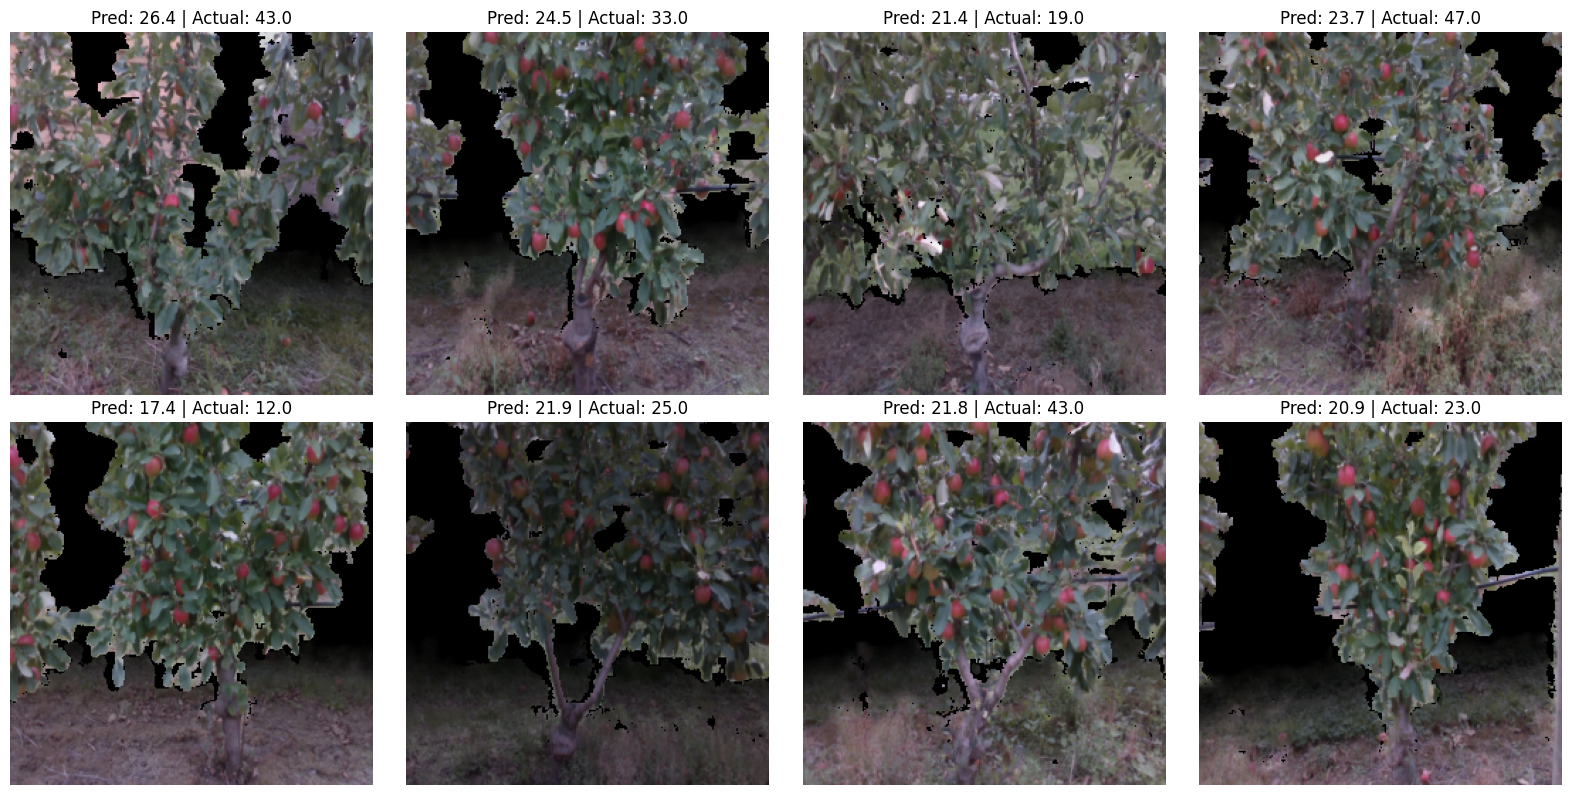

In [21]:
import matplotlib.pyplot as plt

model.eval()
test_loss = 0.0
predictions = []
actual_labels = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * inputs.size(0)

        predictions.extend(outputs.cpu().numpy())
        actual_labels.extend(targets.cpu().numpy())

test_loss /= len(test_loader.dataset)
print(f"Final Test MSE Loss: {test_loss:.4f}")

# Plot a few visual examples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i in range(min(8, len(test_dataset))):
    gated_img, label = test_dataset[i]
    # Convert tensor back to image format (C, H, W) -> (H, W, C)
    np_img = gated_img.permute(1, 2, 0).numpy()
    np_img = np.clip(np_img, 0, 1)

    # Predict
    pred_input = gated_img.unsqueeze(0).to(device)
    with torch.no_grad():
        pred_count = model(pred_input).item()

    axes[i].imshow(np_img)
    axes[i].set_title(f"Pred: {pred_count:.1f} | Actual: {label:.1f}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### 6. Improving Accuracy with Transfer Learning and Data Augmentation
In this section, we apply standard enhancements to boost regression performance:
- **Data Augmentation**: `RandomHorizontalFlip` and `ColorJitter` on the training set.
- **Pre-trained Backbone**: We load a pre-trained `resnet18` and replace its final fully connected layer for single-output regression.
- **Cosine Annealing LR Scheduler**: Dynamically scales down the learning rate.

In [22]:
import torchvision.models as models

# Define robust training transforms with augmentation
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
])

# Validation and testing transforms (no augmentations besides resizing)
val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# Re-create datasets and data loaders with augmentations
train_dataset_aug = AppleCountingDataset(train_pairs, transform=train_transform, is_train=True)
val_dataset_aug = AppleCountingDataset(val_pairs, transform=val_transform, is_train=False)
test_dataset_aug = AppleCountingDataset(test_pairs, transform=val_transform, is_train=False)

train_loader_aug = DataLoader(train_dataset_aug, batch_size=16, shuffle=True)
val_loader_aug = DataLoader(val_dataset_aug, batch_size=16, shuffle=False)
test_loader_aug = DataLoader(test_dataset_aug, batch_size=16, shuffle=False)

# Define a Transfer Learning Model based on ResNet18
class ResNetAppleCounter(nn.Module):
    def __init__(self):
        super(ResNetAppleCounter, self).__init__()
        # Load pre-trained ResNet18 weights
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        # Replace the final fully connected layer for regression
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.backbone(x).squeeze(-1)

In [23]:
# Instantiate and set up optimization tools for the improved model
improved_model = ResNetAppleCounter().to(device)
criterion = nn.MSELoss()
optimizer = optim.AdamW(improved_model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

epochs = 10
print("Training the improved Transfer Learning model...")
for epoch in range(epochs):
    improved_model.train()
    train_loss = 0.0
    for inputs, targets in train_loader_aug:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = improved_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader_aug.dataset)
    scheduler.step()

    # Validation Phase
    improved_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader_aug:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = improved_model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
    val_loss /= len(val_loader_aug.dataset)

    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


Training the improved Transfer Learning model...
Epoch 1/10 - Train Loss: 881.7228 | Val Loss: 1090.9753
Epoch 2/10 - Train Loss: 771.2008 | Val Loss: 985.1879
Epoch 3/10 - Train Loss: 657.8187 | Val Loss: 865.8278
Epoch 4/10 - Train Loss: 541.9598 | Val Loss: 817.4847
Epoch 5/10 - Train Loss: 431.0089 | Val Loss: 694.5599
Epoch 6/10 - Train Loss: 354.8162 | Val Loss: 657.5187
Epoch 7/10 - Train Loss: 294.6463 | Val Loss: 570.4356
Epoch 8/10 - Train Loss: 261.3668 | Val Loss: 590.8009
Epoch 9/10 - Train Loss: 241.2357 | Val Loss: 549.8846
Epoch 10/10 - Train Loss: 232.0964 | Val Loss: 540.5242


In [24]:
# Evaluate the improved model on the test dataset
improved_model.eval()
test_loss_imp = 0.0
with torch.no_grad():
    for inputs, targets in test_loader_aug:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = improved_model(inputs)
        loss = criterion(outputs, targets)
        test_loss_imp += loss.item() * inputs.size(0)

test_loss_imp /= len(test_loader_aug.dataset)
print(f"Original Test MSE Loss: {test_loss:.4f}")
print(f"Improved ResNet-18 Test MSE Loss: {test_loss_imp:.4f}")

Original Test MSE Loss: 175.4634
Improved ResNet-18 Test MSE Loss: 383.2757


### 7. Execution of Improvements
Let's run the model training and evaluate the performance.

In [40]:
import copy

# Re-instantiate the model to reset weights
improved_model = ResNetAppleCounter().to(device)
criterion = nn.MSELoss()
optimizer = optim.AdamW(improved_model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

epochs = 10
best_val_loss = float('inf')
best_model_weights = None

print("Training the improved Transfer Learning model...")
for epoch in range(epochs):
    improved_model.train()
    train_loss = 0.0
    for inputs, targets in train_loader_aug:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = improved_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader_aug.dataset)
    scheduler.step()

    # Validation Phase
    improved_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader_aug:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = improved_model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
    val_loss /= len(val_loader_aug.dataset)

    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    # Track and save the model with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(improved_model.state_dict())
        print(f" --> New best model saved with Val Loss: {best_val_loss:.4f}")

# Load the best weights back into the model
if best_model_weights is not None:
    improved_model.load_state_dict(best_model_weights)
    print("Successfully loaded the best model weights based on lowest validation loss!")

Training the improved Transfer Learning model...
Epoch 1/10 - Train Loss: 873.3871 | Val Loss: 1066.6758
 --> New best model saved with Val Loss: 1066.6758
Epoch 2/10 - Train Loss: 760.6522 | Val Loss: 919.6746
 --> New best model saved with Val Loss: 919.6746
Epoch 3/10 - Train Loss: 638.1469 | Val Loss: 800.5547
 --> New best model saved with Val Loss: 800.5547
Epoch 4/10 - Train Loss: 519.6657 | Val Loss: 641.9378
 --> New best model saved with Val Loss: 641.9378
Epoch 5/10 - Train Loss: 413.0158 | Val Loss: 595.1586
 --> New best model saved with Val Loss: 595.1586
Epoch 6/10 - Train Loss: 333.9346 | Val Loss: 698.0752
Epoch 7/10 - Train Loss: 274.9001 | Val Loss: 677.6989
Epoch 8/10 - Train Loss: 235.1481 | Val Loss: 582.3788
 --> New best model saved with Val Loss: 582.3788
Epoch 9/10 - Train Loss: 228.6196 | Val Loss: 563.0342
 --> New best model saved with Val Loss: 563.0342
Epoch 10/10 - Train Loss: 218.6412 | Val Loss: 538.5829
 --> New best model saved with Val Loss: 538.582

In [41]:
# Evaluate the newly trained best model on the test set
improved_model.eval()
test_loss_imp = 0.0
with torch.no_grad():
    for inputs, targets in test_loader_aug:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = improved_model(inputs)
        loss = criterion(outputs, targets)
        test_loss_imp += loss.item() * inputs.size(0)

test_loss_imp /= len(test_loader_aug.dataset)
print(f"Original Test MSE Loss: {test_loss:.4f}")
print(f"Best ResNet-18 Test MSE Loss (lowest val loss model): {test_loss_imp:.4f}")

Original Test MSE Loss: 175.4634
Best ResNet-18 Test MSE Loss (lowest val loss model): 373.0046


### 8. Export Count Predictions to Excel
We will use the trained ResNet-18 model to predict apple counts for all trees in our dataset (or a specific set like the test set), calculate the total number of apples, and save the output to an Excel file.

In [27]:
import pandas as pd
import torch
import os

# Put model in evaluation mode
improved_model.eval()

results = []

# We will iterate through the test dataset and predict counts for each tree (image file)
with torch.no_grad():
    for i, (rgb_path, d_path) in enumerate(test_pairs):
        # Get the individual sample from test dataset
        gated_img, label = test_dataset_aug[i]
        pred_input = gated_img.unsqueeze(0).to(device)

        # Generate prediction
        pred_count = improved_model(pred_input).item()

        # Extract the tree identifier (filename prefix)
        file_prefix = os.path.basename(rgb_path).split('_Summer')[0]

        results.append({
            'Tree ID': file_prefix,
            'Predicted Apple Count': round(pred_count, 2),
            'Synthetic Ground Truth Count': round(float(label), 2),
            'RGB Image Path': rgb_path
        })

# Create a DataFrame
df_export = pd.DataFrame(results)

# Calculate the total number of predicted apples
total_predicted = df_export['Predicted Apple Count'].sum()

# Add a summary row at the bottom
summary_row = pd.DataFrame([{
    'Tree ID': 'TOTAL',
    'Predicted Apple Count': round(total_predicted, 2),
    'Synthetic Ground Truth Count': round(df_export['Synthetic Ground Truth Count'].sum(), 2),
    'RGB Image Path': 'N/A'
}])

df_final = pd.concat([df_export, summary_row], ignore_index=True)

# Export to Excel
excel_filename = '/content/apple_counts.xlsx'
df_final.to_excel(excel_filename, index=False)

print(f"Excel file saved successfully to {excel_filename}!")
display(df_final)

Excel file saved successfully to /content/apple_counts.xlsx!


,Tree ID,Predicted Apple Count,Synthetic Ground Truth Count,RGB Image Path
0,R01U03,8.98,43.0,/content/split_dataset/summer_rgb/test/R01U03_...
1,R01U14,6.76,33.0,/content/split_dataset/summer_rgb/test/R01U14_...
2,R01U19,8.93,19.0,/content/split_dataset/summer_rgb/test/R01U19_...
3,R03U10,8.46,47.0,/content/split_dataset/summer_rgb/test/R03U10_...
4,R04U18,7.10,12.0,/content/split_dataset/summer_rgb/test/R04U18_...
5,R05U15,9.68,25.0,/content/split_dataset/summer_rgb/test/R05U15_...
6,R09U07,9.35,43.0,/content/split_dataset/summer_rgb/test/R09U07_...
7,R12U02,12.21,23.0,/content/split_dataset/summer_rgb/test/R12U02_...
8,R13U02,8.75,27.0,/content/split_dataset/summer_rgb/test/R13U02_...
9,R13U04,11.71,15.0,/content/split_dataset/summer_rgb/test/R13U04_...


### 10. Diagnose Unmatched Images
This script identifies the exact image files (RGB or Depth) that did not find a matching pair based on their file prefixes, helping us spot naming anomalies.

In [29]:
import os

# Extract names from unmatched pools
rgb_names = {os.path.basename(f).split('_Summer')[0]: f for f in rgb_images}
d_names = {os.path.basename(f).split('_Summer')[0]: f for f in d_images}

# Find mismatches
missing_depth_for_rgb = [prefix for prefix in rgb_names if prefix not in d_names]
missing_rgb_for_depth = [prefix for prefix in d_names if prefix not in rgb_names]

print(f"Diagnosing Match Discrepancies:")
print(f"- Number of RGB prefixes: {len(rgb_names)}")
print(f"- Number of Depth prefixes: {len(d_names)}")
print(f"- RGB images missing a matching Depth counterpart: {len(missing_depth_for_rgb)}")
print(f"- Depth images missing a matching RGB counterpart: {len(missing_rgb_for_depth)}")

if missing_depth_for_rgb:
    print(
        "\nExamples of RGB prefixes missing Depth images (first 10):",
        missing_depth_for_rgb[:10]
    )
if missing_rgb_for_depth:
    print(
        "\nExamples of Depth prefixes missing RGB images (first 10):",
        missing_rgb_for_depth[:10]
    )

Diagnosing Match Discrepancies:
- Number of RGB prefixes: 544
- Number of Depth prefixes: 544
- RGB images missing a matching Depth counterpart: 0
- Depth images missing a matching RGB counterpart: 0
